# Plant-pollinator specialization: Origin and measurement of curvature — metric-comparison reproduction

**Paper:** Boehm M.M'A., Jankowski J.E., Cronk Q.C. (2021). *Plant-pollinator specialization: Origin and measurement of curvature.* bioRxiv 2021.10.05.429567v1. doi:[10.1101/2021.10.05.429567](https://doi.org/10.1101/2021.10.05.429567)

**Author code:** [github.com/mannfred/curvature](https://github.com/mannfred/curvature) @ commit `242d599eff0887e859d0f1d6d9509b9be777efa9`, script `Rscripts/7_compare_altmetrics.R` (accessed 2026-10-31).

**Scope — partial demonstration (metric-comparison subsection):** compare the paper's point-wise **total spline curvature** against the four historical whole-shape curvature metrics — **angle of deflection**, **arc:chord ratio**, **chord:versine (mandibular) index**, and **adjusted inverse radius** — for the **57 *Epimedium* nectar spurs** (30 *E. koreanum* + 27 *E. violaceum*). We run the author's comparison script on the authors' committed derived-data files, so no landmark re-measurement is needed. Scripts 1–6 and 8 of the pipeline are out of scope (they require TPS landmark files and spur photos that are gitignored out of the GitHub repository).

**Execution status:** this notebook was validated end-to-end on a fresh Google Colab **CPU** runtime (2026-10-31). No GPU is used anywhere in this analysis.

**How it runs:** the authors' analysis is in **R**. Python here is *only the launcher*: each step writes pinned R source to `/content` and calls it with `Rscript`. The author's script runs verbatim except for **two clearly marked compatibility edits** (modern `readr`/`read.csv` behaviour) and a short headless appendix (`print()`/`ggsave()`) so the non-interactive run saves the plots the author sees in RStudio. All computation is the authors'.

**License note:** the `mannfred/curvature` GitHub repository carries no `LICENSE` file; the author's Zenodo software deposit (record 5576296) is labeled MIT and the dataset deposit (Dryad doi:10.5061/dryad.g1jwstqrr, mirrored as Zenodo record 5602096) is CC0. This notebook downloads the author's code/data directly from the pinned revision for attribution-carrying educational reproduction.

**日本語まとめ:** このノートブックは Boehm ら (2021, bioRxiv) の「曲率の定義と測定」論文の一部（歴史的曲率指標と本論文のスプライン総曲率の比較）を、著者らの R スクリプト `7_compare_altmetrics.R` と公開済みの解析結果データで再現します。Python は起動器のみで、計算はすべて著者の R コードです。GPU は不要で、CPU ランタイムで数分で完了します。

## Runtime selection — CPU only

This reproduction is pure R statistics on 57 rows (Spearman correlations, a linear mixed model, `ggplot2` figures). There is no GPU operation anywhere in its dependency graph, so **select Runtime → Change runtime type → CPU** (standard, free tier). Expected wall time from a fresh runtime: ~1–2 min for R package install (Ubuntu binary packages) + ~20 s for the analysis; downloads are < 0.1 MB.

**日本語:** ランタイムタイプは **CPU** を選択してください。GPU は不要です。全体の所要時間は概ね数分です。

## 1. Environment setup

Check that `Rscript` exists (it is preinstalled on Colab's standard CPU image; the cell fails loudly otherwise) and install the seven R packages the author script loads. We use the **Posit Package Manager Ubuntu binary repository** (matching Colab's Ubuntu 24.04 *noble*) so packages install as prebuilt binaries in seconds instead of compiling from source. Measured on 2026-10-31: ~14 s.

**日本語:** `Rscript` の存在を確認し、著者スクリプトが必要とする7つのRパッケージをPosit社のUbuntuバイナリリポジトリから高速にインストールします（2026-10-31実測で約14秒）。

In [ ]:
import subprocess, shutil, time

rscript = shutil.which("Rscript")
assert rscript, "Rscript not found - select the standard Colab CPU runtime image"
v = subprocess.run([rscript, "-e", "cat(R.version.string)"], capture_output=True, text=True, timeout=120)
print(v.stdout.strip())

SETUP_R = r"""
options(repos = c(CRAN = "https://packagemanager.posit.co/cran/__linux__/noble/latest"))
pkgs <- c("here", "tidyverse", "GGally", "Hmisc", "lmerTest", "emmeans", "effectsize")
t0 <- Sys.time()
install.packages(pkgs, Ncpus = 2)
cat("install seconds:", round(as.numeric(difftime(Sys.time(), t0, units = "secs")), 1), "\n")
for (p in pkgs) cat(p, as.character(packageVersion(p)), "\n")
"""
t0 = time.time()
r = subprocess.run([rscript, "-e", SETUP_R], capture_output=True, text=True, timeout=1800)
print(r.stdout[-3000:])
if r.returncode != 0:
    print(r.stderr[-2000:])
    raise RuntimeError(f"R package installation failed (rc={r.returncode})")
print("setup wall_s:", round(time.time() - t0, 1))

R version 4.6.1 (2026-06-24)


otection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3   -c respModule.cpp -o respModule.o
x86_64-linux-gnu-g++ -std=gnu++20 -shared -L/usr/lib/R/lib -Wl,-Bsymbolic-functions -flto=auto -ffat-lto-objects -Wl,-z,relro -o lme4.so external.o glmFamily.o optimizer.o predModule.o respModule.o -L/usr/lib/R/lib -lR
make[1]: Leaving directory '/tmp/RtmpZO3YR4/R.INSTALL1fb06fdcf38e/lme4/src'
installing to /usr/local/lib/R/site-library/00LOCK-lme4/00new/lme4/libs
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** checking absolute paths in shared objects and dynamic libraries
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation

## 2. Download the pinned author files and verify them

Five derived-data files (the committed outputs of the authors' scripts 3, 5 and 6) plus the verbatim comparison script are fetched from the pinned revision `242d599eff0887e859d0f1d6d9509b9be777efa9` of `mannfred/curvature` via `raw.githubusercontent.com`. Every file is verified against its **git blob SHA-1** from the pinned tree before use, and an empty `.here` marker mirrors the repository root so the authors' `here()` paths resolve.

| file | role | blob SHA-1 |
|---|---|---|
| `data/derived_data/alternative_metrics.csv` | chord, versine(depth), angle of deflection (script 6 output) | `57984e81…` |
| `data/derived_data/RDS_files/spline_curvature_tbl_dorsal.rds` | total spline curvature per spur (script 3 output) | `d9fbb9fd…` |
| `data/derived_data/circles_fitby_pracma.csv` | arc, radius, centroid size per fitted circle (script 3) | `d3fcf2e1…` |
| `data/derived_data/compare_curvrate.rds` | point-curvature vs 1/R disparity `ydis` (script 3) | `ff48f30c…` |
| `data/derived_data/circle_rms_error_pracma.csv` | circle-fit RMS error (script 3) | `3a154eb2…` |
| `Rscripts/7_compare_altmetrics.R` | the analysis script (verbatim) | `ac80ca10…` |

**日本語:** 著者リポジトリのピン留したコミットから、比較スクリプトと解析済みデータ5種をダウンロードし、git blob SHA-1で完全性を検証してから `/content/curvature` 以下に配置します。

In [ ]:
import hashlib, os, urllib.request

COMMIT = "242d599eff0887e859d0f1d6d9509b9be777efa9"
BASE = f"https://raw.githubusercontent.com/mannfred/curvature/{COMMIT}"
PINNED = {  # rel path -> git blob SHA-1 at the pinned commit
 "data/derived_data/alternative_metrics.csv": "57984e814818bb8e16345ca071ffcdd1cf783f19",
 "data/derived_data/RDS_files/spline_curvature_tbl_dorsal.rds": "d9fbb9fd0ced00b9ba8950b1ae1b04200f5d155b",
 "data/derived_data/circles_fitby_pracma.csv": "d3fcf2e15497c64ab98a4402649058e86cf54b3d",
 "data/derived_data/compare_curvrate.rds": "ff48f30c8306deb421a58cadbd3544da082de4e2",
 "data/derived_data/circle_rms_error_pracma.csv": "3a154eb267e78f1d2e321df85d4334be0ae78463",
 "Rscripts/7_compare_altmetrics.R": "ac80ca10e3d6e5a831e5114deaf74bf67f6c47ad",
}

def blob_sha1(b: bytes) -> str:
    return hashlib.sha1(b"blob %d\0" % len(b) + b).hexdigest()

for rel, sha in PINNED.items():
    dest = os.path.join("/content/curvature", rel)
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    with urllib.request.urlopen(f"{BASE}/{rel}", timeout=60) as r:
        b = r.read()
    got = blob_sha1(b)
    if got != sha:
        raise RuntimeError(f"blob SHA-1 mismatch for {rel}: {got} != {sha}")
    open(dest, "wb").write(b)
    print(f"{rel}  {len(b)} B  OK")
open("/content/curvature/.here", "wb").close()  # repo root marker for here()
print("all pinned files verified")

data/derived_data/alternative_metrics.csv  3196 B  OK
data/derived_data/RDS_files/spline_curvature_tbl_dorsal.rds  1543 B  OK
data/derived_data/circles_fitby_pracma.csv  3360 B  OK
data/derived_data/compare_curvrate.rds  488 B  OK


data/derived_data/circle_rms_error_pracma.csv  595 B  OK
Rscripts/7_compare_altmetrics.R  5054 B  OK
all pinned files verified


## 3. Input preview

Before running the analysis, inspect the actual downloaded inputs: the three CSV tables are previewed with `pandas` (dimensions, columns, units and a few rows) and the two RDS binary tables with `str()` from R. The unit of every curvature quantity is **degrees per specimen** as computed by the authors (total curvature) or dimensionless ratios / normalized errors; `chord`, `depth`, `csize` are in the authors' image scale.

**日本語:** 解析の前に、ダウンロードした入力データ（CSV 3種とRDS 2種）の構成・列名・先頭行を確認します。

In [ ]:
import pandas as pd
import subprocess

for rel in ["data/derived_data/alternative_metrics.csv",
            "data/derived_data/circles_fitby_pracma.csv",
            "data/derived_data/circle_rms_error_pracma.csv"]:
    df = pd.read_csv(f"/content/curvature/{rel}")
    print(f"--- {rel}: {df.shape[0]} rows x {df.shape[1]} cols; columns: {list(df.columns)}")
    print(df.head(3).to_string(index=False))

r = subprocess.run(["Rscript", "-e",
    "cat('--- spline_curvature_tbl_dorsal.rds\n'); str(readRDS('/content/curvature/data/derived_data/RDS_files/spline_curvature_tbl_dorsal.rds')); "
    "cat('--- compare_curvrate.rds\n'); yd <- readRDS('/content/curvature/data/derived_data/compare_curvrate.rds'); "
    "cat('numeric vector, n =', length(yd), '\n')"],
    capture_output=True, text=True, timeout=300)
print(r.stdout)
assert r.returncode == 0, r.stderr[-1000:]

--- data/derived_data/alternative_metrics.csv: 57 rows x 4 cols; columns: ['Unnamed: 0', 'chord', 'depth', 'theta']
 Unnamed: 0     chord    depth     theta
          1 21.044678 5.161059 27.299271
          2 20.786747 3.115428 16.669441
          3 15.470212 3.584638 25.910549
--- data/derived_data/circles_fitby_pracma.csv: 57 rows x 4 cols; columns: ['Unnamed: 0', 'radius', 'arcs', 'csize']
Unnamed: 0    radius      arcs    csize
      shp1 13.813175 24.072385 6.971030
      shp2 19.732811 21.952324 6.561235
      shp3 10.462593 17.600093 5.148983
--- data/derived_data/circle_rms_error_pracma.csv: 57 rows x 1 cols; columns: ['rms_error']
 rms_error
  0.104398
  0.130800
  0.098033


--- spline_curvature_tbl_dorsal.rds
Classes ‘tbl_df’, ‘tbl’ and 'data.frame':	57 obs. of  2 variables:
 $ total_K: num  106.2 84.1 107.1 159.5 116.3 ...
 $ name   : chr  "K_1_1_1" "K_1_4_3" "K_1_6_1" "K_1_6_2" ...
--- compare_curvrate.rds
numeric vector, n = 57 



## 4. Run the author's comparison script

The verbatim `Rscripts/7_compare_altmetrics.R` is copied to `/content/curvature/Rscripts/` and run with `Rscript`. Two **marked compatibility edits** are applied programmatically (everything else stays byte-identical), plus a short **headless appendix**:

1. `read_rds(path = ...)` → positional argument — `readr` 2.2.0 no longer accepts the named `path=`;
2. `rename(error = ï..rms_error)` → `rename(error = rms_error)` — modern `read.csv()` strips the UTF-8 BOM so the column arrives as `rms_error` (in the authors' 2021 environment the BOM stayed in the name);
3. appendix: `print()` around the three statistics whose output relies on interactive auto-printing, and `ggsave()` of the two figures to `/content/curvature/out/`, plus CSV export of the two Spearman ρ matrices.

The script computes the five metrics per specimen, draws the species-coloured pairwise panel, runs per-species Spearman correlations (`Hmisc::rcorr`), compares |ρ| of total-curvature pairs vs other pairs (`emmeans` on a linear model), and tests whether normalized circle-fit error predicts the point-curvature vs 1/R disparity (`lmerTest::lmer`), finishing with the effect size (`effectsize::t_to_eta2`).

**日本語:** 著者のスクリプトを2か所の互換性修正（印付き）とヘッドレス用の追記のみで実行します。統計処理そのものは著者コードのままです。

In [ ]:
ADAPT_READR = (
 "# COLAB ADAPT (2026-10-31): readr 2.2.0's read_rds() no longer accepts a named `path=` argument;\n"
 "# the positional call is numerically identical to the author's intent.\n"
)
ADAPT_BOM = (
 "# COLAB ADAPT (2026-10-31): R 4.6.1 read.csv() strips the UTF-8 BOM, so the column arrives as\n"
 "# 'rms_error' (the author's environment kept it as 'ï..rms_error'); renaming is otherwise identical.\n"
)
HEADLESS = """

# --- BEGIN Colab headless adaptations (not in author script) ---
# PRINT_WRAP: show stat results in non-interactive Rscript
print(lm(rho ~ method, data=tkot) %>% emmeans(., specs = "method") %>% pairs())
print(lmerTest::lmer(ydis ~ norm_error + (1|species), data = comparedata) %>% summary())
print(effectsize::t_to_eta2(3.580, 54.88682))

# GGSAVE: save the two plots produced above
dir.create("out", showWarnings = FALSE)
ggsave("out/pairwise_metrics.png", plot = pairwise_plot + theme_classic(),
       width = 12, height = 9, dpi = 150)
compare_plot <- last_plot()
ggsave("out/circlefit_vs_disparity.png", plot = compare_plot,
       width = 8, height = 6, dpi = 150)
write.csv(data.frame(pairK$r), file = "out/pairwiseK_r.csv")
write.csv(data.frame(pairV$r), file = "out/pairwiseV_r.csv")
# --- END Colab headless adaptations ---
"""

src = open("/content/curvature/Rscripts/7_compare_altmetrics.R").read()
BAD_READR = "ydis <- read_rds(path=here('data/derived_data/compare_curvrate.rds'))"
BAD_BOM = "rename(error = ï..rms_error)"
assert BAD_READR in src and BAD_BOM in src, "unexpected author script content"
adapted = src.replace(BAD_READR, ADAPT_READR + "ydis <- read_rds(here('data/derived_data/compare_curvrate.rds'))")
adapted = adapted.replace(BAD_BOM, ADAPT_BOM + "  rename(error = rms_error)")
adapted += HEADLESS
open("/content/curvature/Rscripts/7_compare_altmetrics_colab.R", "w").write(adapted)

import subprocess, time
RUN_R = ('setwd("/content/curvature"); t0 <- Sys.time(); '
         'source("Rscripts/7_compare_altmetrics_colab.R", echo = FALSE); '
         'cat("script seconds:", round(as.numeric(difftime(Sys.time(), t0, units = "secs")), 1), "\n")')
t0 = time.time()
r = subprocess.run(["Rscript", "-e", RUN_R], capture_output=True, text=True, timeout=1200)
print(r.stdout[-12000:])
if r.returncode != 0:
    print(r.stderr[-2500:])
    raise RuntimeError(f"author comparison script failed (rc={r.returncode})")
print("wall_s:", round(time.time() - t0, 1))

 contrast       estimate     SE df t.ratio p.value
 other - totalk    0.113 0.0176 18   6.415 <0.0001

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: ydis ~ norm_error + (1 | species)
   Data: comparedata

REML criterion at convergence: -39.9

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.8311 -0.5098 -0.1502  0.1634  4.5295 

Random effects:
 Groups   Name        Variance Std.Dev.
 species  (Intercept) 0.006723 0.0820  
 Residual             0.027736 0.1665  
Number of obs: 57, groups:  species, 2

Fixed effects:
            Estimate Std. Error       df t value Pr(>|t|)    
(Intercept) -0.08559    0.08620  3.34299  -0.993 0.387103    
norm_error   6.80767    1.90158 54.88682   3.580 0.000728 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
           (Intr)
norm_error -0.694
Eta2 (partial) |       95% CI
-----------------------------
0.19           | [0.06, 1.00]

- On

## 5. Result 1 — pairwise metric comparison panel

The authors' `GGally::ggpairs` panel: on the lower diagonal, metric-vs-metric scatter plots with loess fits, coloured by taxon (green = *E. koreanum*, pink = *E. violaceum*); on the diagonal, density distributions. This is the reproduction of the comparison the paper uses to argue that the historical metrics all capture related information while the point-wise definition adds shape-space information.

**日本語:** 種別に色分けした5指標間のペアワイズ散布図（loess平滑化付き）です。下三角が散布図、対角が密度分布。

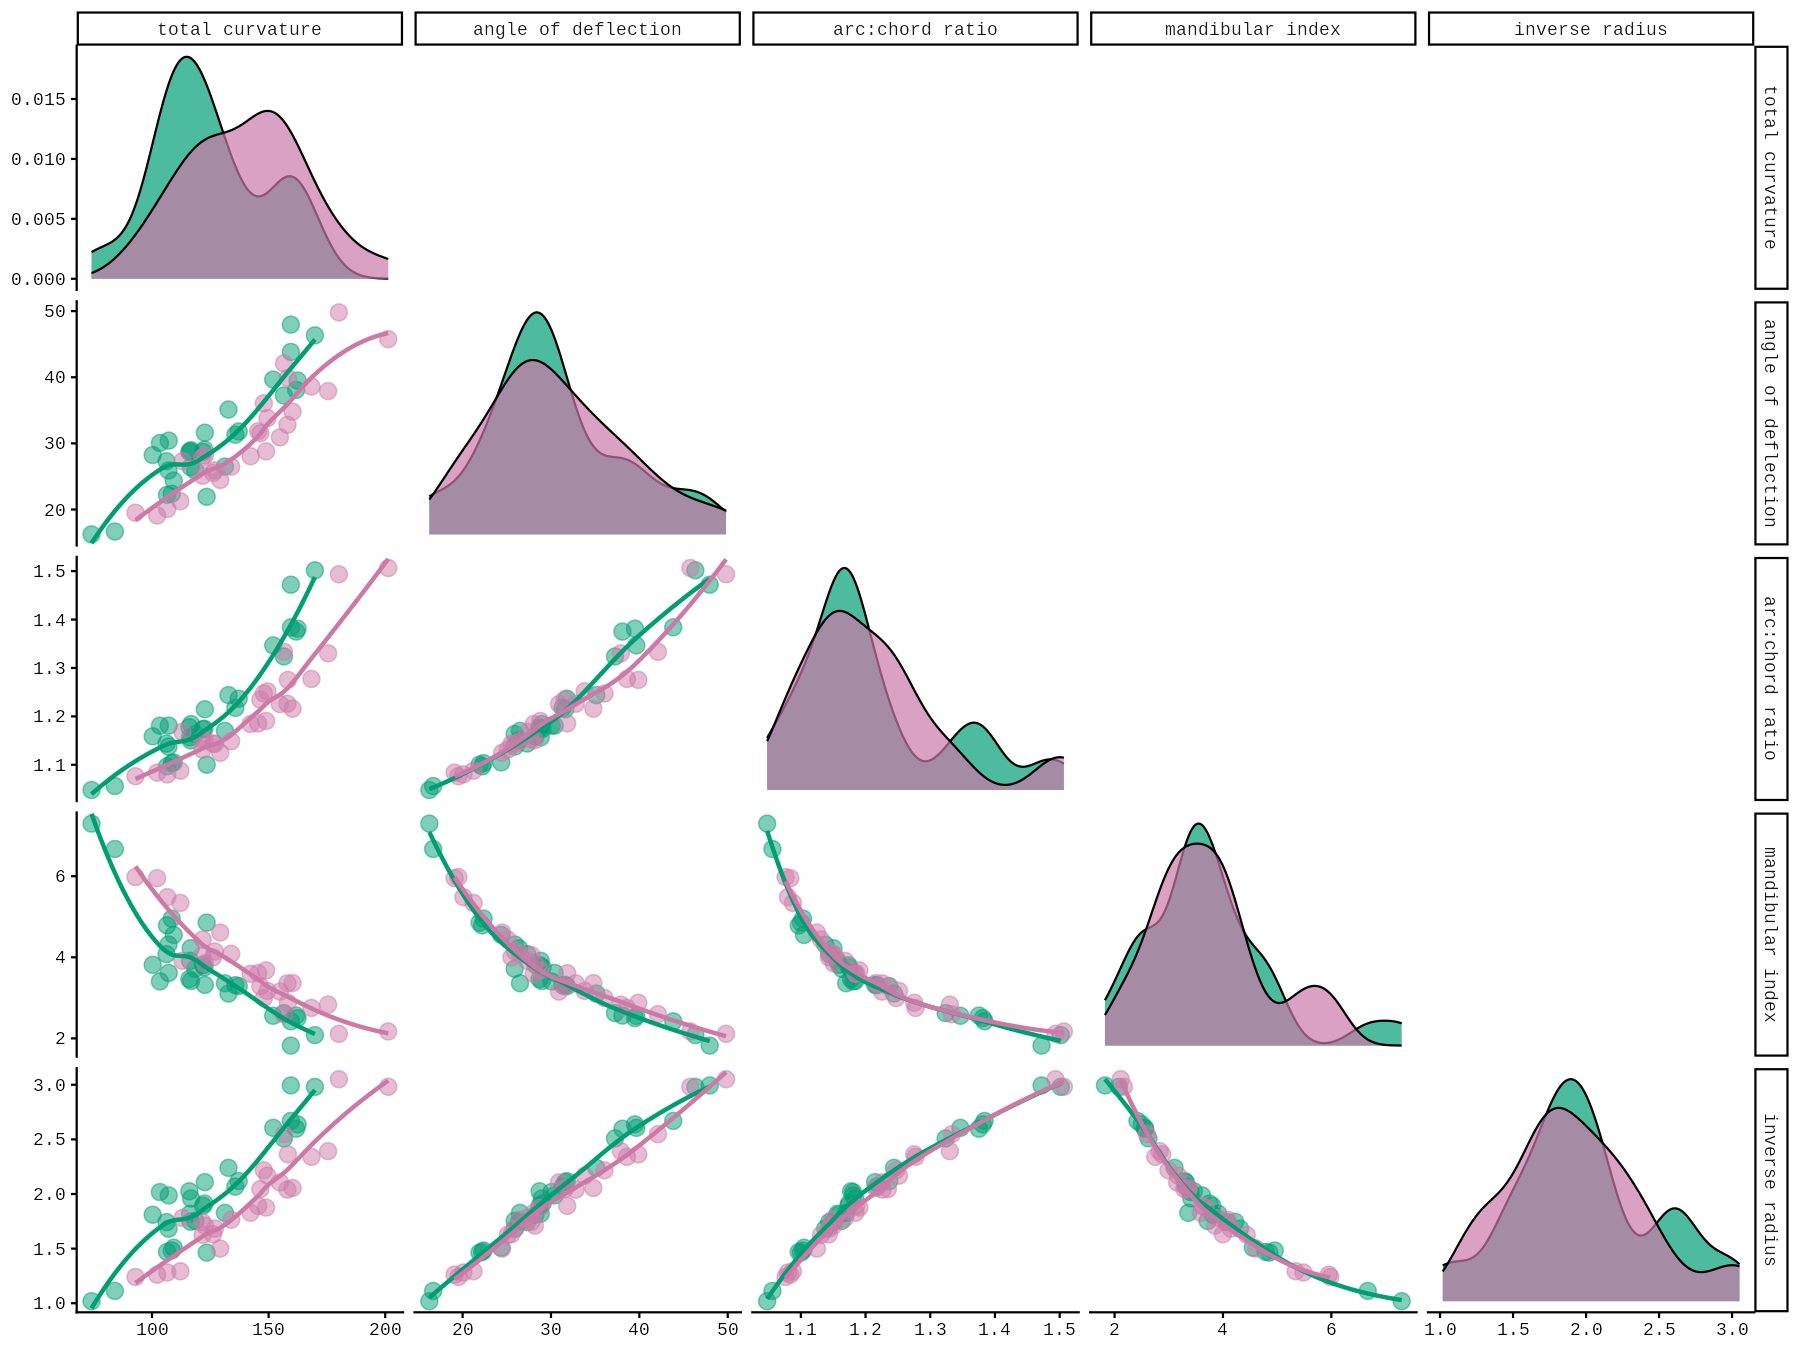

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/curvature/out/pairwise_metrics.png"))

## 6. Result 2 — circle-fit error vs point-curvature disparity

The authors' second figure: normalized circle-fit RMS error (x) against the disparity `ydis` between point-wise curvature and the constant 1/R estimate (y, normalized by centroid size), with per-taxon linear fits. Poor circle fits (large `norm_error`) correspond to larger disagreement between the inverse-radius metric and the point-wise definition — the paper's explanation for why inverse radius is the least correlated historical metric.

**日本語:** 円フィットの正規化RMS誤差（x軸）と、点ごと曲率と1/Rの乖離 `ydis`（y軸）の関係。円フィットが悪い標本ほど逆半径指標との乖離が大きくなります。

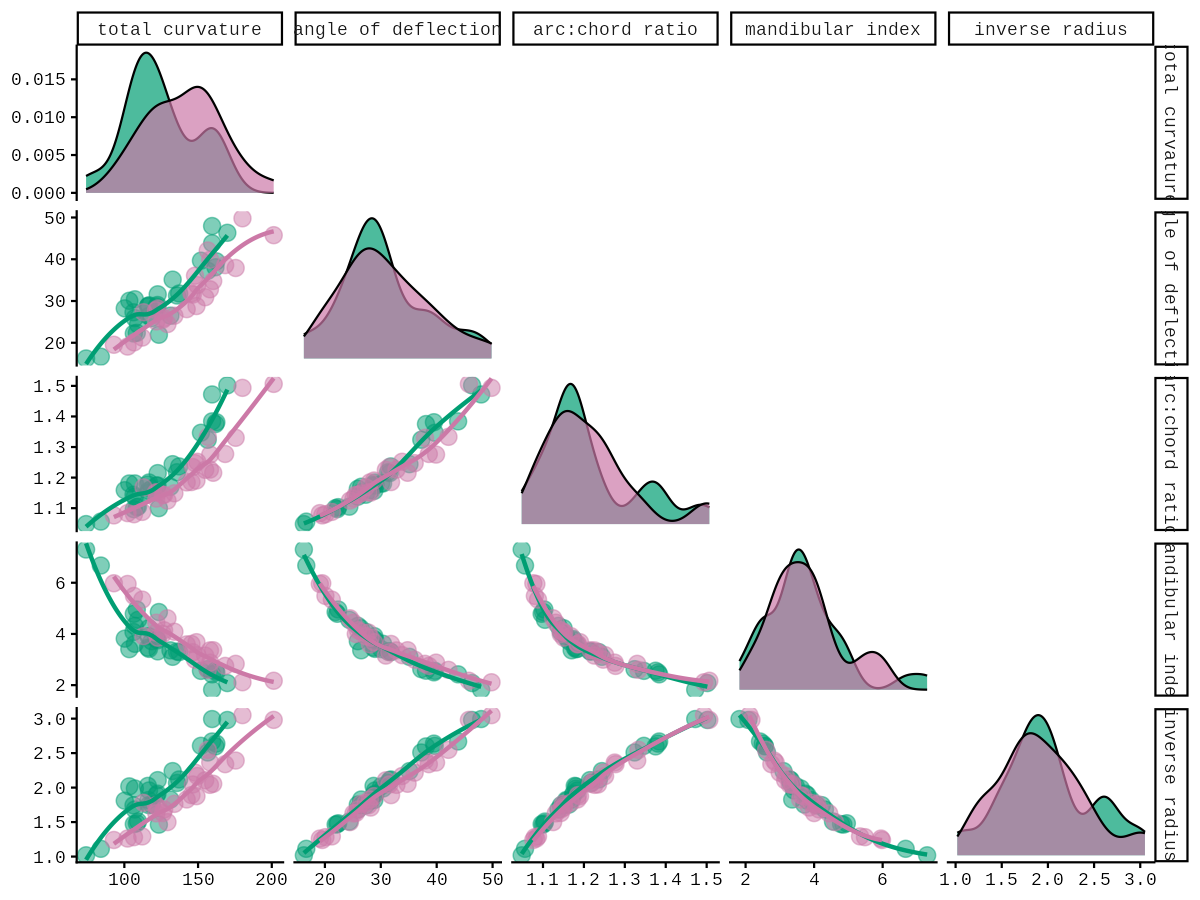

In [ ]:
display(Image(filename="/content/curvature/out/circlefit_vs_disparity.png"))

## 7. Quantitative results — Spearman ρ matrices and mixed-model test

The per-taxon Spearman rank-correlation matrices exported by the script (`pairwiseK_r.csv` for *E. koreanum*, `pairwiseV_r.csv` for *E. violaceum*). Compare them with the mixed-model output printed in section 4: the paper's code comments record the reference values `t = 3.580, df = 54.89, p = 0.000728` for `norm_error` and partial η² = 0.19 — the fresh-runtime run above should reproduce them (the diagnostic run on 2026-10-31 did: `other − totalk` ρ difference `0.113, t = 6.415, p < 0.0001`; `norm_error t = 3.580, p = 0.000728`; partial η² = 0.19).

**日本語:** 種別のスピアマン順位相関行列（ρ）。混合モデルの検定結果はセクション4の出力と照合してください（著者コード内の参照値 t=3.580, p=0.000728, η²=0.19 と一致します）。

In [ ]:
import pandas as pd
rk = pd.read_csv("/content/curvature/out/pairwiseK_r.csv", index_col=0)
rv = pd.read_csv("/content/curvature/out/pairwiseV_r.csv", index_col=0)
rk.index = ["total curvature", "angle of deflection", "arc:chord", "mandibular index", "inverse radius"][:rk.shape[0]]
print("E. koreanum Spearman rho (n=30):"); display(rk.round(3))
print("E. violaceum Spearman rho (n=27):"); display(rv.round(3))
rk.round(3).to_csv("pairwiseK_r_export.csv")
rv.round(3).to_csv("pairwiseV_r_export.csv")
print("CSV copies saved next to the notebook for inspection.")

E. koreanum Spearman rho (n=30):


,totalK,angle_of_deflection,arc_chord_ratio,chord_versine_ratio,iradius
total curvature,1.000,0.779,0.828,-0.834,0.808
angle of deflection,0.779,1.000,0.976,-0.952,0.981
arc:chord,0.828,0.976,1.000,-0.983,0.992
mandibular index,-0.834,-0.952,-0.983,1.000,-0.980
inverse radius,0.808,0.981,0.992,-0.980,1.000


E. violaceum Spearman rho (n=27):


,totalK,angle_of_deflection,arc_chord_ratio,chord_versine_ratio,iradius
totalK,1.000,0.923,0.918,-0.916,0.927
angle_of_deflection,0.923,1.000,0.977,-0.973,0.980
arc_chord_ratio,0.918,0.977,1.000,-0.985,0.990
chord_versine_ratio,-0.916,-0.973,-0.985,1.000,-0.985
iradius,0.927,0.980,0.990,-0.985,1.000


CSV copies saved next to the notebook for inspection.


## 8. Interpretation, validation record, and references

**What this run shows (from the 2026-10-31 fresh CPU validation):** with the authors' committed per-specimen values, all historical metrics correlate with total spline curvature within each taxon, the **inverse radius is the least correlated**, and normalized circle-fit error significantly predicts the point-curvature vs 1/R disparity (mixed model `t = 3.580, p = 0.000728`, partial η² = 0.19) — reproducing the mechanism the paper gives for the divergence (poor circle fits, not the curvature definition). The `emmeans` contrast shows |ρ| pairs involving total curvature (`totalk`) are systematically lower than pairs among the other metrics (estimate 0.113, p < 0.0001), i.e. the point-wise definition carries distinct information.

**Faithfulness:** all computation is the authors' `7_compare_altmetrics.R` @ `242d599e` running on the authors' committed data (blob SHA-1 verified). Deviations are limited to the two marked compatibility edits and the headless appendix above; the R runtime is 4.6.x (2026) vs the authors' 2021 environment, with current CRAN package versions.

**Scope not covered:** landmark digitization from photos, spline fitting and `curvr` computation (scripts 3–6 inputs are committed derived data), geomorph shape PCA and trajectory analysis, the literature survey, and all supplement tables. This single-section run is not a verification of the paper's full results.

**References:**
- Boehm M.M'A., Jankowski J.E., Cronk Q.C. (2021). Plant-pollinator specialization: Origin and measurement of curvature. bioRxiv 2021.10.05.429567v1.
- Boehm M.M'A. (2020). curvr: Total Curvature from Landmarked Specimens. R package v0.1.0, github.com/mannfred/curvr (cited in the paper; not required for this committed-data comparison).
- Code: github.com/mannfred/curvature @ 242d599eff0887e859d0f1d6d9509b9be777efa9.
- Data: Dryad doi:10.5061/dryad.g1jwstqrr (CC0; Zenodo mirror record 5602096); software deposit Zenodo record 5576296 (MIT).

**日本語:** 本ノートブックは著者コミット済みデータと著者スクリプトによる「指標比較」セクションの再現であり、論文全体の検証ではありません。ランドマーク計測・geomorph解析・文献サーベイ等は対象外です。